<a id="TMP_836b"></a>

# <span style="color:rgb(213,80,0)">Simple Quadcopter Propeller Model</span>

[⇦ Main Menu](MainMenu.mlx)

When modeling a quadcopter, the propeller is a component that uses a motor to convert electrical energy into mechanical thrust. A good propeller model must be simple enough for control design while being physically meaningful. We therefore start with the simplest useful propeller model that takes into account units and scaling. Complexity can be introduced later.

<!-- Begin Toc -->

## Table of Contents
&#8195;[Motivation](#TMP_6c14)

&#8195;[Momentum theory](#TMP_4aff)

&#8195;&#8195;[Blade element reasoning](#TMP_53d2)

&#8195;&#8195;[Dimensional analysis](#TMP_0e5b)

&#8195;&#8195;[Modeling assumptions](#TMP_14fb)

&#8195;[Thrust model](#TMP_412c)

&#8195;[Reaction (drag) torque model](#TMP_5fee)

&#8195;&#8195;[Drag on a blade element](#TMP_8381)

&#8195;&#8195;[Torque](#TMP_731e)

&#8195;[Impact on Quadcopter Design](#TMP_7c77)

&#8195;&#8195;[Further Design Considerations](#TMP_103f)

&#8195;[Local Helper Functions](#H_0AAABA39)

<!-- End Toc -->
<a id="TMP_63f5"></a>
This live script is intended to be used with the code visible and output inline. On the **View** tab of the MATLAB Toolstrip, in the **View** section, select **Output Inline**. Alternately, select **Output Inline** using the icon  at the top right of the Live Editor pane.

<a id="TMP_6c14"></a>

## Motivation

You change only one thing on a quadcopter: replace all four 5‑inch propellers with 10‑inch propellers. Can you predict how the new quadcopter will behave? Let's explore this question with both local (blade element) and global (momentum theory) approaches. If we approach the problem at both scales and reach the same conclusion, that is an additional indication that the underlying fundamentals agree.

<a id="TMP_4aff"></a>

## Momentum theory

First, consider a global approach where we model the propeller as an actuator disk

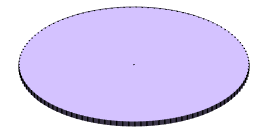 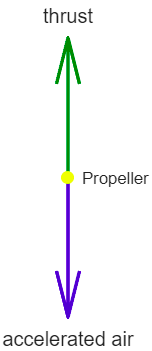

that accelerates air downward. Then

 $\dot{m} =\rho Av=\rho \pi r^2 v$,

where

- $\dot{m}$ = mass flow rate of air \[kg/s\]
- $v$ = downward air velocity \[m/s\]
- $\rho$ = the mass density of air \[kg/m^3\]
- $r$ = the radius of the propeller \[m\]

The air speed induced by the propeller scales with blade tip speed, so $v\propto\omega r$ where $\omega$ is the radial velocity in radians per second. This gives us

 $\dot{m} \propto\rho \pi r^3 \omega$.

The induced velocity change is also proportional to $\omega r$. From Newton's second law, the thrust force, $T$, can be expressed as:

$$T=\dot{m} \Delta v$$

 $T\propto\rho \pi r^2 (\omega r)^2 =\rho \pi r^4 \omega^2$.

<p style="text-align:left">
   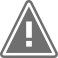**Note:** [Some derivations](https://ocw.mit.edu/ans7870/16/16.unified/propulsionS04/UnifiedPropulsion7/UnifiedPropulsion7.htm) use the diameter of the propeller rather than the radius. Recall that for a diameter $D$, we can write $r=\frac{D}{2}$, so $T\propto\rho \pi {\left(\frac{D}{2}\right)}^4 \omega^2$. This also gives a fourth-order dependence of the thrust on the propeller diameter, simply by changing the constant factor.
</p>

<a id="TMP_53d2"></a>

### Blade element reasoning

Let's also consider a local approach, where we look at one small blade section at radius $x$. The local tangential speed is $v(x)=\omega x$. The dynamic pressure is $q=\frac{1}{2}\rho v^2 =\frac{1}{2}\rho \omega^2 x^2$. The incremental thrust on the blade element is proportional to the dynamic pressure times the area element, $dA=c(x)\;dx$ where $c(x)$ is the cross\-sectional width of the propeller at radius $x$.  A geometrically similar blade is one where every cross‑section is the *same airfoil*, just shrunk or stretched. Real propellers break geometric similarity near the root and the tip. Still, for a simple model we'll assume that geometric similarity holds. This means that $c(x)/r$ is a constant, so $c\proptor$. Therefore, the incremental thrust is:

$$\begin{array}{ccc} dT & \propto & q\cdot c(x)\;dx\newline dT & \propto & \rho \omega^2 x^2 r\;dx. \end{array}$$

Then the total thrust is

$$\begin{array}{ccc} T & \propto & \int_0^r \rho \omega^2 x^2 r\;dx\newline  & \propto & \rho \omega^2 r^4 .~~~~~\; \end{array}$$

**Pro\-Tip:** Different propeller designs make different choices for $c$, from an inefficient $c=\textrm{constant}$ that puts lots of pressure on the tips of propellers to a better $c=c_0 \left(1-k\frac{x}{r}\right)$ or an even better $c\propto\sqrt{1-{\left(\frac{x}{r}\right)}^2 }$ to create propellers with more uniform force along their length.

<a id="TMP_0e5b"></a>

### Dimensional analysis

We want thrust, $T$, which, as a force, has units of $\textrm{kg}\cdot \textrm{m}/{\textrm{s}}^2$. The components to include are:

- Mass density $\rho$  \[ $\textrm{kg}/{\textrm{m}}^3$ \]
- Angular speed $\omega$  \[ $1/\textrm{s}$ \]
- Propeller radius $r$  \[ $\textrm{m}$ \].

The only way to combine these elements to create the correct dimensions is if $T\propto\rho r^4 \omega^2$. For purposes of numerical computation, we can define a dimensionless coefficient $C_T$ such that $T=C_T \rho r^4 \omega^2$. By measuring the thrust of a specific propeller at a known speed $\omega$, we can compute $C_T$ and model the thrust as we change the radius, the mass density, and the rotational speed within the domain where the model makes sense.

<a id="TMP_14fb"></a>

### Modeling assumptions

We assumed:

1. The propeller has rigid, fixed‑pitch blades $\to$ the geometric assumptions are constant
2. Flow is incompressible $\to$ the value of $\rho$ is constant
3. Thrust acts along the propeller axis $\to$ the propeller is fixed\-pitch
4. No blade flapping, no induced velocity modeling $\to$ the geometric assumptions are constant

These assumptions are valid for:

- Subsonic flow
- Forward speed is small (hover or slow flight)
- Props are fixed‑pitch
- Reynolds numbers are moderate

<a id="TMP_412c"></a>

## Thrust model

These assumptions give us the simplest physically meaningful thrust model as:

 $T=k_T \omega^2$.

Where:

- $T$ = thrust force \[N\]
- $\omega$ = angular speed of the propeller \[rad/s\]
- $k_T$ = $C_T \rho r^4$ is a thrust coefficient \[N/(rad/s)\textasciicircum{}2\]

**Physical interpretation**

- Faster rotation → higher blade tip speed
- Higher tip speed → larger dynamic pressure
- The resulting thrust grows quadratically with $\omega$

<p style="text-align:left">
   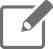 **Exercise 1.**
</p>

What propeller speed is required for a quadcopter of mass $M=0.54$ kg with a thrust coefficient of $k_T =1.072\times 10^{-5}$ to hover? Use $g=9.81\;\textrm{m}/{\textrm{s}}^2$. Call your solution `omega_hover`.

**Solution:**


In [1]:
% Write code to implement your calculation here.
% Replace the default value of omega_hover = 0 with the value you compute for omega_hover.
% Then run this section to execute the CheckEx1 function for feedback.
M = 0.54; % kg
g = 9.81;
kT = 1.072e-5;


% Above formula with T = mg becomes
omega_hover = sqrt(M*g/(4*kT)); % This value should be your propeller speed in rad/s
% This function will check your computed value of omega_hover
CheckEx1(omega_hover)

Correct! The calculated hover speed matches the expected value.
The propeller needs to be rotating at approximately 351 rad/s or 3356 rpm.


<a id="TMP_5fee"></a>

## Reaction (drag) torque model

Let $V_{\textrm{a}} (x)$ be the local inflow velocity. For a hovering propeller, this inflow velocity is just the tangential component $V_{\textrm{a}} (x)=\omega x$.

<p style="text-align:left">
   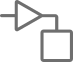 **Pro-tip (Advanced considerations).** The [aerodynamic propeller block](https://www.mathworks.com/help/sdl/ref/aerodynamicpropeller.html) will be the fundamental propeller used in our models throughout this courseware. Note the distinctions between thrust, lift, drag, and torque, as well as the airflow through the propeller, $V_a$, and the speed of the vehicle $V_v$.
</p>

When forward motion is involved, the airflow, ${\vec{V} }_{\textrm{a}} =\omega x\hat{\theta} +\left(V_v +v_i \right)\hat{z}$, picks up an additional perpendicular term that can be expressed in terms of the aircraft forward speed, $V_v$,  and the induced axial velocity through the disk, $v_i$. Thus, in general, $V_{\textrm{a}} =\sqrt{(\omega x)^2 +(V_v +v_i )^2 }$, so when $\omega x>>V_v$, such as when the forward velocity is 0, it is reasonable to approximate $V_{\textrm{a}} \approx \omega x$. However, in forward flight this changes. Near the hub, $\omega x$ is small so $V_v$ will dominate with $V_{\textrm{a}} \approx V_v +v_i$, but near the tip, rotation will still dominate with $V_{\textrm{a}} \approx \omega x$.

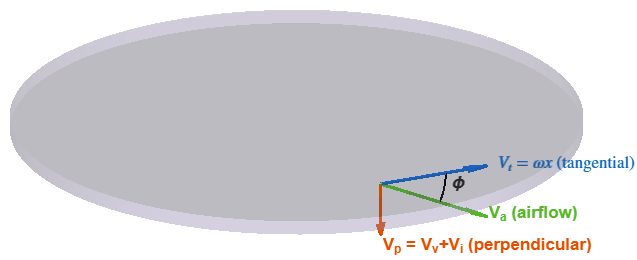

<p style="text-align:left">
   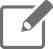 **Exercise 2.** Define the inflow angle $\phi$ by $\tan (\phi )=\frac{V_v +v_i }{\omega x}$.
</p>

a. Near the hub, the value of $\phi$:


In [2]:
CheckEx2("increases","a")

Correct.


b. Near the tip, the value of $\phi$:


In [3]:
CheckEx2("decreases","b");

Correct.
Unrecognized function or variable 'displayFormula'.
displayFormula requires Symbolic Math Toolbox.
Error in PropellerModel>CheckEx2 (line 81)
            displayFormula('"This dependence on radial distance is why forward-flight propellers must be twisted."')


For a blade element at radius $x$, the local Reynolds number is

 $\textrm{Re}(x)=\frac{\rho V_{\textrm{a}} (x)c(x)}{\mu }$.

**Cautionary Note (Aerodynamic Theory):** The Reynolds number depends on both geometry (chord $c$ ) and kinematics (local velocity $V_{\textrm{a}}$ ). This means that even geometrically similar propeller blades can operate in different Reynolds regimes. Blade\-element theory assumes that if the geometry is similar, then the section aerodynamics are similar. This assumption is only valid when the thrust coefficient and the torque coefficient are Reynolds\-insensitive over the operating range. At a low Reynolds number, stalls occur earlier, the maximum thrust coefficient is lower, drag is higher, and laminar separation bubbles appear. Even on a single blade, because of the proportionality to $V_{\textrm{a}} \cdot c$, there will be Reynolds number variation from near 0 towards the shaft and much higher near the tip. This means that inner blade sections may exhibit low\-Re aerodynamics while the outer sections behave as classical airfoils. Careful shaping of the propeller blade can minimize the effects, but as the modeling fidelity improves, it will be important to consider this.

<a id="TMP_8381"></a>

### Drag on a blade element

For a blade element at radius $x$ with width $dx$, the incremental section drag force is

 $dD=\frac{1}{2}\rho V_{\textrm{a}}^2 (x)c(x)C_Q \;dx$.

where $C_Q$ is the torque coefficient, which depends on factors including the Reynolds number. For propeller analyses near the hover regime,

 $V_{\textrm{a}} (x)\approx \omega x$.

So, by substitution, we have an $x$ \-dependence of

 $\frac{dD}{dx}\proptox^2 c(x)C_Q$,

because $C_Q$ is not constant along the blade due to its dependence on the Reynolds number.

<a id="TMP_731e"></a>

### Torque

Since torque is force times moment arm, the incremental torque is $dQ=xdD$, or in other words

 $\frac{dQ}{dx}=\frac{1}{2}\rho V_{\textrm{a}}^2 (x)c(x)C_Q x$.

In the near\-hover domain, this can be simplified to

 $\frac{dQ}{dx}\proptoC_Q \omega^2 x^3 c(x)$    and thus, when $c\proptor$,     $Q\proptoC_Q \omega^2 r^5$.

More generally, $Q\propto\int_0^r \frac{1}{2}\omega^2 x^3 c(x)C_Q \;dx$ and thus, the power $P$ required by the propeller can be expressed as $P=\omega Q\propto\int_0^r \frac{1}{2}\omega^3 x^3 c(x)C_Q \;dx$.

As the propeller spins, aerodynamic drag produces a reaction torque on the motor shaft:

$$Q=k_m \omega^2$$

Where:

- $Q$ = torque resisting rotation \[N $\cdot$ m\]
- $k_m$ = drag (moment) coefficient including $C_Q r^5$.

<a id="TMP_7c77"></a>

## Impact on Quadcopter Design

Torque acts about the axis of rotation, causing the yaw motion of the vehicle. For a quadcopter, because torque acts in a direction opposite to the spin of the propeller, balanced operation requires paired sets of counter\-rotating propellers. The thrust acts in the opposite direction to the air jet.

We encode the direction of rotation with a sign $\epsilon =\pm 1$:

$$Q_z =\epsilon \,k_m \,\omega^2$$

<a id="M_262c"></a>

In [4]:
function [T,Q] = SimplePropellerModel(omega, kT, km, spinDir)
% SimplePropellerModel
% Simple quadcopter propeller model
%
% Inputs:
%   omega   - rotational speed [rad/s]
%   kT      - thrust coefficient [N/(rad/s)^2]
%   km      - drag coefficient   [N*m/(rad/s)^2]
%   spinDir - +1 (CCW) or -1 (CW)
%
% Outputs:
%   T       - thrust force [N]
%   Q       - reaction torque about axis of rotation [N*m]


T   = kT * omega.^2;
Q = spinDir * km * omega.^2;
end


<p style="text-align:left">
    **Try**. With given values of $k_T$ and $k_m$, use the [simple propeller model](#M_262c) to observe the relationships between rotational speed, thrust, and drag torque by running this section of code.
</p>



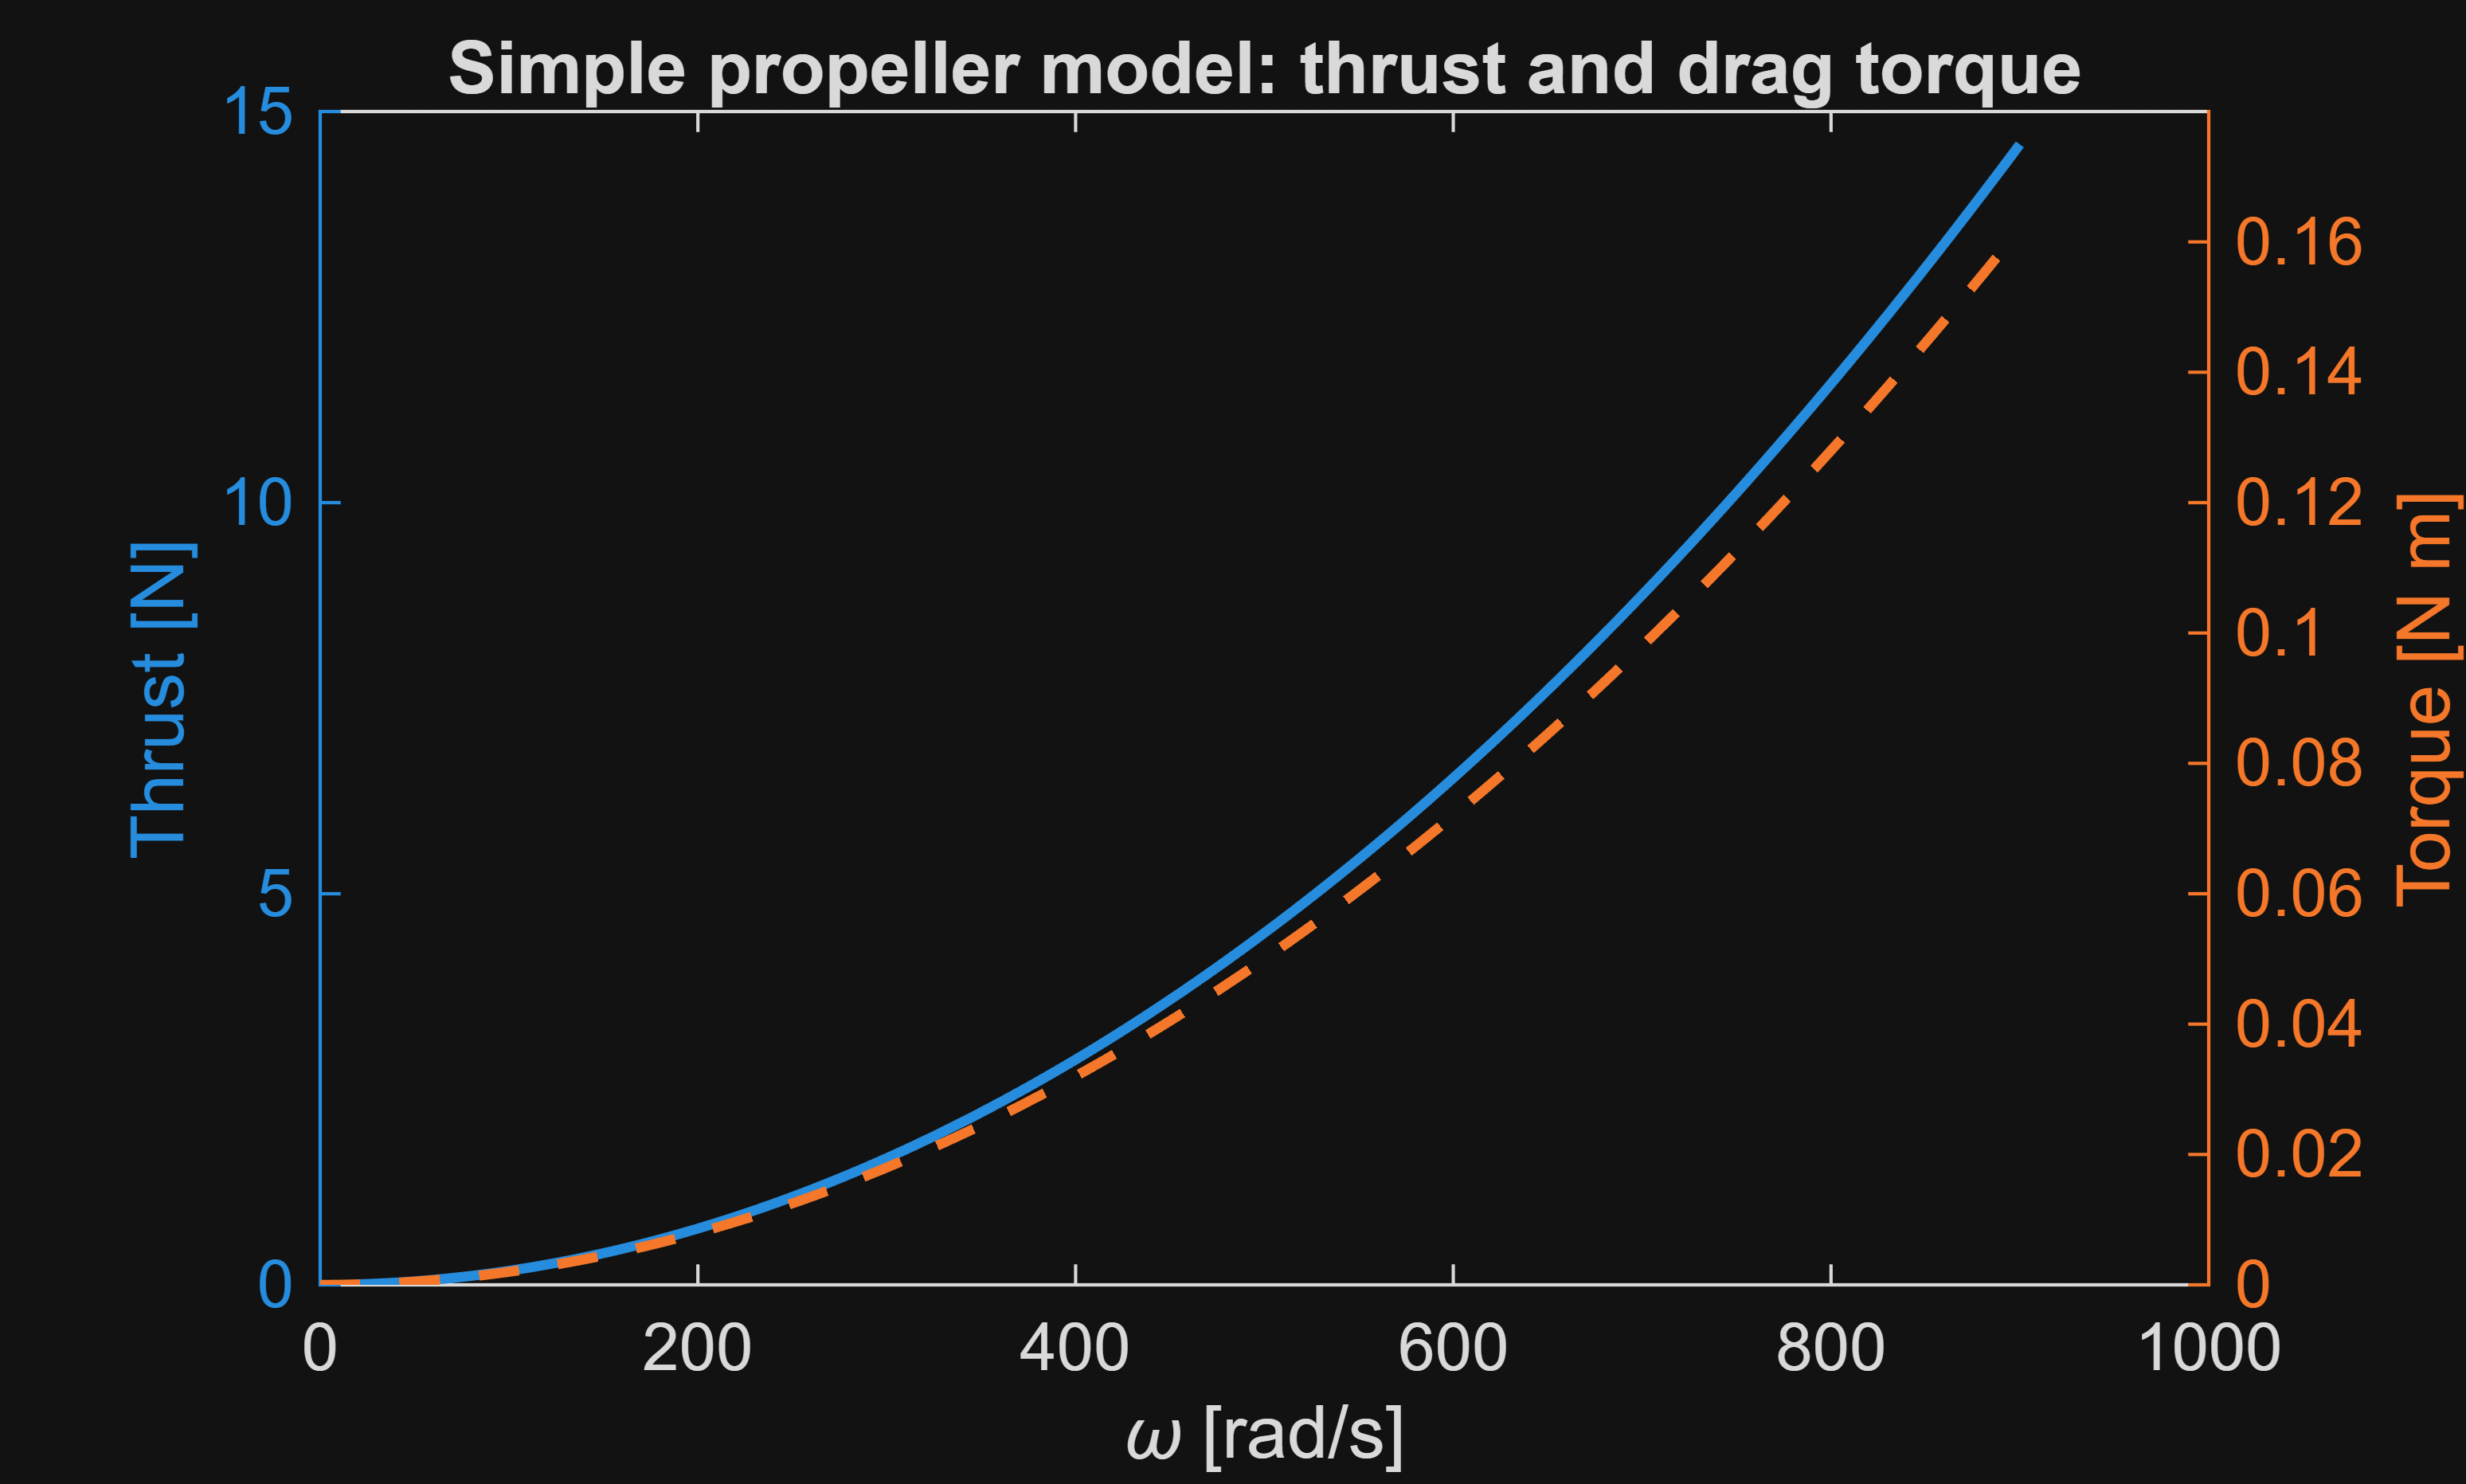

In [5]:
kT = 1.8e-5;
km = 2.0e-7;
omega = linspace(0,900,200);
spinDir = 1;


[T,Q] = SimplePropellerModel(omega, kT, km, spinDir);


figure
yyaxis left
plot(omega, T, "LineWidth",1.5);
ylabel("Thrust [N]");


yyaxis right
plot(omega, Q, "--", "LineWidth",1.5);
ylabel("Torque [N m]");


xlabel("\omega [rad/s]");
title("Simple propeller model: thrust and drag torque");


<p style="text-align:left">
   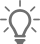 **Reflect**. Why does thrust increase much faster than torque for the same increase in $\omega$?
</p>

<p style="text-align:left">
   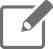 **Exercise 3.** Build a Simulink model implementing the simple propeller model.
</p>

- Use constant inputs of $\omega$, $k_m$, $k_T$, and $\epsilon$
- Implement the formulas from `SimplePropellerModel` using Simulink blocks. Split signals, as needed.
- Output values for thrust and torque in display blocks.


In [6]:
open("SimplePropellerModel.slx");


<a id="TMP_103f"></a>

### Further Design Considerations

There are many parameters to consider in propeller design that go far beyond the discussions here. More of the equations and details are described in the documentation for the [Aerodynamic Propeller block](https://www.mathworks.com/help/sdl/ref/aerodynamicpropeller.html).

[⇦ Main Menu](MainMenu.mlx)

<a id="H_0AAABA39"></a>

## Local Helper Functions

In [7]:
function CheckEx1(speed)
M = 0.54; % kg
g = 9.81;
kT = 1.072e-5;
omega_hover = sqrt(M*g/(4*kT));
if abs(omega_hover-speed) < 5e-1
    disp("Correct! The calculated hover speed matches the expected value.")
    disp("The propeller needs to be rotating at approximately " + round(speed) + " rad/s or " + round(60*speed/(2*pi)) + " rpm.")
elseif abs(omega_hover^2-speed) < 1e-3
    disp("Incorrect. Did you remember the square root?")
elseif abs(omega_hover*2 - speed) < 1e-3
    disp("Incorrect. Did you remember that a quadcopter has four propellers?")
elseif speed == 0
    disp("This is the default value. Please compute a nonzero speed.")
else
    disp("Incorrect. Please check your calculation and try again.")
end
end


function CheckEx2(Soln,Part)
arguments
    Soln (1,1) string {mustBeMember(Soln,["default","decreases","same","increases"])}
    Part (1,1) string {mustBeMember(Part,["a" "b"])}
end


switch Soln
    case "default"
        disp("This is the default. Please answer the question.")
    case "decreases"
        if Part=="b"
            disp("Correct.")
            displayFormula('"This dependence on radial distance is why forward-flight propellers must be twisted."')
        else
            disp("Incorrect.")
            displayFormula(['"Remember that the angle "' "phi" '" approaches 0 as "' "tan(phi)" '" approaches 0."'])
        end
    case "same"
        disp("Incorrect.")
        displayFormula(['"How can the angle "' "phi" '" not change when it depends on the value of x?"'])
    case "increases"
        if Part == "a"
            disp("Correct.")
        else
            disp("Incorrect.")
            displayFormula(['"Remember that "' "phi" '" approaches "' "pi/2" '" as "' "tan(phi)" '" approaches infinity."'])
        end
end
end